# Random Forest • NeuroTriagem.AI

**Notebook de desenvolvimento e integração — demonstração sintética por padrão.**

O detector facial já possui rótulos de normalidade e graus de assimetria. Ainda
não há uma base das cinco medições associadas a desfechos clínicos independentes.
Nesta versão, a floresta
aprende a **imitar regras explícitas sobre cenários sintéticos**, conforme o objetivo
escolhido para o protótipo. As classes `DEMO_*` não representam AVC nem sua ausência.
As métricas medem fidelidade às regras, **não são desempenho clínico**.

O notebook prepara um `RandomForestClassifier` para as cinco medições já disponíveis
no aplicativo. O mesmo pipeline de pré-processamento é usado no treino e na inferência.
Os batimentos cardíacos (BPM) já entram nesta versão; o ECG fica para uma etapa futura.
Ao final, teremos um artefato versionado, um relatório e um exemplo de integração.
Não é necessário câmera, placa ou acesso à internet durante a execução.

**Preparação (na raiz do projeto, PowerShell):**
```powershell
.\.venv\Scripts\python.exe -m pip install -r requirements-notebooks.txt
.\.venv\Scripts\python.exe -m jupyterlab notebooks/random_forest_neurotriagem.ipynb
```
Execute as células na ordem, pelo kernel Python desse ambiente.

## 1. O que aproveitamos das referências

- O [artigo MDPI](https://doi.org/10.3390/computers13050125) aborda regressão de
  pressão arterial a partir de atributos PPG. Inspira a organização entre aquisição,
  atributos, ajuste e inferência; seu alvo não corresponde à triagem neurológica.
- O [artigo de ECG](https://pdfs.semanticscholar.org/2abe/2d06f2b718e92f4a2b2427442ff7fbc6041c.pdf)
  inspira o registro em CSV e a análise em Jupyter. Sua lógica embarcada de limiares
  e resultados cardíacos não validam o classificador deste projeto.
- O conteúdo do [link IEEE](https://ieeexplore.ieee.org/document/11546535) não pôde
  ser recuperado. Não foram presumidos seu título, método ou resultados.

A análise e os limites de cada referência estão em
[`docs/random_forest_referencias.md`](../docs/random_forest_referencias.md).
Esta implementação é uma adaptação de engenharia, não uma reprodução dos estudos.

### Pesquisa clínica e definição do experimento atual

A [pesquisa dos parâmetros](../docs/evidencias_avc_parametros.md) distingue sinais de
alerta de diagnóstico e prognóstico. A [avaliação de bases públicas](../docs/bases_avc_avaliadas.md)
não localizou uma base aberta diretamente compatível com estas cinco entradas.

| Referência ou parâmetro | Uso estritamente experimental |
|---|---|
| Face/braço como sinais no [B.E. F.A.S.T.](https://www.stroke.org/en/about-stroke/stroke-symptoms) | Motiva investigar essas modalidades; não valida as saídas da câmera |
| `arm_ratio > 0.6` | Limiar de engenharia já existente no código; não é corte clínico |
| Código de lado > 0 ou classe facial > 0 | Convenção do projeto para cenários com sinal motor; não equivale ao NIHSS |
| BPM < 60 ou > 100 | Fora da faixa usual de repouso indicada pela [AHA](https://www.heart.org/en/health-topics/high-blood-pressure/the-facts-about-high-blood-pressure/all-about-heart-rate-pulse); não indica AVC |
| SpO₂ < 95% | Abaixo da faixa informada para a maioria das pessoas saudáveis pela [FDA](https://www.fda.gov/consumers/consumer-updates/pulse-oximeter-basics); não diagnostica AVC |

Regras definidas antes do treino: sinal motor se qualquer condição motora for
verdadeira; faixa vital se qualquer condição vital for verdadeira. Ausência de
qualquer entrada produz a classe técnica `DEMO_DADOS_INCOMPLETOS`.

| Classe sintética | Significado no simulador |
|---|---|
| `DEMO_MOTOR_E_VITAL` | As duas regras acionadas |
| `DEMO_SINAL_MOTOR` | Apenas a regra motora acionada |
| `DEMO_FAIXA_VITAL` | Apenas a regra de faixa vital acionada |
| `DEMO_SEM_REGRA_ACIONADA` | Nenhuma das regras acionada; **não exclui AVC** |
| `DEMO_DADOS_INCOMPLETOS` | Uma ou mais entradas ausentes; não significa ausência de sinais |

O gerador não representa prevalência, correlações fisiológicas ou casos clínicos.
Como o alvo vem das próprias entradas, há uma tarefa de imitação, deliberadamente
circular para fins diagnósticos. A função de regras tem concordância de 100% por
construção; a floresta é uma aproximação que pode cometer erros. Se o objetivo for
apenas executar essas regras, a função determinística é a referência exata.

In [1]:
from pathlib import Path
from collections import Counter
from itertools import product
import csv
import hashlib
import html
import json
import platform
import sys

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import sklearn
from IPython.display import HTML, display
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay

# Funciona abrindo o Jupyter na raiz ou na pasta notebooks.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "core" / "random_forest_model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Abra este notebook dentro da pasta do projeto NeuroTriagem.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from core.random_forest_model import (
    FEATURE_NAMES, DEFAULT_MODEL_PATH, RiscoRandomForest, save_artifact,
)
from core.random_forest_training import load_dataset, train_evaluate
from core.random_forest_rules import (
    RULE_VERSION, RULE_CONFIG, SOURCE_URLS, make_rule_demo_dataset, label_rule_scenarios,
)

DISPLAY_LABELS = {
    "DEMO_MOTOR_E_VITAL": "Motor + vital", "DEMO_SINAL_MOTOR": "Motor",
    "DEMO_FAIXA_VITAL": "Faixa vital", "DEMO_SEM_REGRA_ACIONADA": "Sem regra",
    "DEMO_DADOS_INCOMPLETOS": "Incompletos",
}
def display_label(value):
    return DISPLAY_LABELS.get(str(value), str(value))

def table(headers, rows):
    def cell(value):
        return html.escape(str(value))
    head = "".join(f"<th>{cell(h)}</th>" for h in headers)
    body = "".join("<tr>" + "".join(f"<td>{cell(v)}</td>" for v in row) + "</tr>" for row in rows)
    display(HTML(f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"))

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
VERSIONS = {"python": platform.python_version(), "numpy": np.__version__,
            "scikit-learn": sklearn.__version__, "joblib": joblib.__version__,
            "matplotlib": matplotlib.__version__}
table(["Biblioteca", "Versão usada"], VERSIONS.items())

Biblioteca,Versão usada
python,3.11.9
numpy,2.4.6
scikit-learn,1.9.1
joblib,1.6.0
matplotlib,3.11.2


## 2. Configuração e contrato dos dados

Para dados reais, mude `MODO_DEMONSTRACAO` para `False`, indique o CSV e descreva
o desfecho e o procedimento independente de anotação em `DESCRICAO_ALVO_REAL`.
O programa nunca troca silenciosamente uma base real ausente por dados sintéticos.

| Coluna | Definição e unidade | Ausência |
|---|---|---|
| `patient_id` | Identificador pseudônimo estável da pessoa, inclusive em visitas distintas; só para particionar | Não permitida |
| `arm_ratio` | Diferença vertical suavizada entre punhos / largura dos ombros, no fim do teste; ≥ 0, adimensional | Vazio |
| `arm_weak_side_code` | Lado inferido no fim do teste: 0 nenhum, 1 esquerdo, 2 direito | Vazio, não zero |
| `facial_asymmetry_score` | Maior grau reconhecido durante o teste cronometrado (20 s por padrão; ajustável entre 5 e 60 s): 0 normal, 1 leve/atenção, 2 alta/alerta | Vazio antes da conclusão ou sem observação válida |
| `heart_rate` | Frequência cardíaca medida, BPM | Vazio; zero legado também significa ausente |
| `spo2` | Saturação periférica medida, % (0 a 100) | Vazio; zero legado também significa ausente |
| `risco` | Em dados reais, rótulo independente; no simulador, classe `DEMO_*` produzida pela regra | Não permitida |

O modelo de CSV está em [`data/random_forest_template.csv`](../data/random_forest_template.csv).
Use UTF-8, vírgula como separador e ponto decimal. Uma linha representa uma avaliação.
Não substitua `patient_id` pelo número da sessão: repetições da mesma pessoa precisam
ficar no mesmo grupo. ID e rótulo não entram nas features. Colunas extras são ignoradas.

O detector facial já trabalha com **rótulos de normalidade e assimetria**. No
protótipo, eles aparecem como **Normal**, **Atenção — assimetria leve** e
**Alerta — assimetria alta**. Esses rótulos descrevem o sinal observado; no
Random Forest, seu código é uma entrada junto das medidas do braço, BPM e SpO₂.
A regra sintética atual agrupa os graus faciais 1 e 2 como sinal motor; a
categoria facial é mostrada separadamente da previsão da floresta.

O teste facial tem **Iniciar teste** e **Reiniciar teste**, com contagem regressiva.
Só as observações da janela iniciada manualmente entram no resultado; ao concluir,
o maior grau fica congelado. Reiniciar descarta a captura e começa desde zero.
Uma detecção isolada de grau alto pode determinar esse máximo. A duração e a
agregação são escolhas de engenharia, não um protocolo clínico estabelecido.
`FACE_VOTE_WINDOW` continua afetando apenas a prévia do vídeo. Ao preparar uma
base real, registre a duração e use o mesmo protocolo no treino e no aplicativo;
dados antigos resumidos por uma janela móvel não são automaticamente equivalentes.

**O teste de braço já participa do modelo e pode integrar uma futura avaliação
clínica**, comparado com a referência independente do profissional. Fraqueza de
braço e assimetria facial são sinais considerados pelo
[B.E. F.A.S.T.](https://www.stroke.org/en/about-stroke/stroke-symptoms).
Para avaliar detecção de AVC, será necessário relacionar essas medições ao
desfecho clínico independente. Por enquanto, os alvos gerados pelas regras são
adequados ao experimento de imitação escolhido, e as métricas medem essa imitação.
O joystick permanece descritivo; incluí-lo exigirá outro contrato de atributos
e uma base rotulada correspondente.

In [2]:
MODO_DEMONSTRACAO = True
DATASET_PATH = ROOT / "data" / "neurotriagem_rotulada.csv"
TARGET_COLUMN = "risco"
GROUP_COLUMN = "patient_id"
DESCRICAO_ALVO_REAL = ""  # Preencher definição das classes, referência e processo de anotação.
RANDOM_STATE = 42
N_ITER = 8
CV_SPLITS = 3
TEST_SPLITS = 5          # Primeiro fold reservado: aproximadamente 20% para teste.
ATIVAR_NO_APP = False   # Só funciona com dados reais; deixa o modelo experimental.

ARTIFACT_DIR = ROOT / "artifacts"
ARTIFACT_DIR.mkdir(exist_ok=True)
if MODO_DEMONSTRACAO:
    X, y, groups = make_rule_demo_dataset(n_patients=750, random_state=RANDOM_STATE)
    DATA_KIND = "synthetic"
    TARGET_DESCRIPTION = "Imitação de regras motoras/faixas vitais em cenários sintéticos; não detecta AVC."
    PREFIX = "random_forest_regras_experimental"
else:
    if not DESCRICAO_ALVO_REAL.strip():
        raise ValueError("Defina DESCRICAO_ALVO_REAL antes de usar dados reais.")
    X, y, groups = load_dataset(DATASET_PATH, target_column=TARGET_COLUMN, group_column=GROUP_COLUMN)
    DATA_KIND = "real"
    TARGET_DESCRIPTION = DESCRICAO_ALVO_REAL
    PREFIX = "random_forest_candidato"

print("DEMONSTRAÇÃO SINTÉTICA — sem validade clínica" if MODO_DEMONSTRACAO else "DADOS REAIS — modelo experimental")
print(f"{len(X)} avaliações; {len(np.unique(groups))} participantes; {len(np.unique(y))} classes.")
table(["Classe", "Avaliações"], sorted(Counter(y).items()))
table(["Feature", "Valores ausentes", "% ausente"],
      [(name, int(np.isnan(X[:, i]).sum()), f"{np.isnan(X[:, i]).mean():.1%}")
       for i, name in enumerate(FEATURE_NAMES)])

DEMONSTRAÇÃO SINTÉTICA — sem validade clínica
1500 avaliações; 750 participantes; 5 classes.


Classe,Avaliações
DEMO_DADOS_INCOMPLETOS,300
DEMO_FAIXA_VITAL,300
DEMO_MOTOR_E_VITAL,300
DEMO_SEM_REGRA_ACIONADA,300
DEMO_SINAL_MOTOR,300


Feature,Valores ausentes,% ausente
arm_ratio,90,6.0%
arm_weak_side_code,94,6.3%
facial_asymmetry_score,80,5.3%
heart_rate,86,5.7%
spo2,86,5.7%


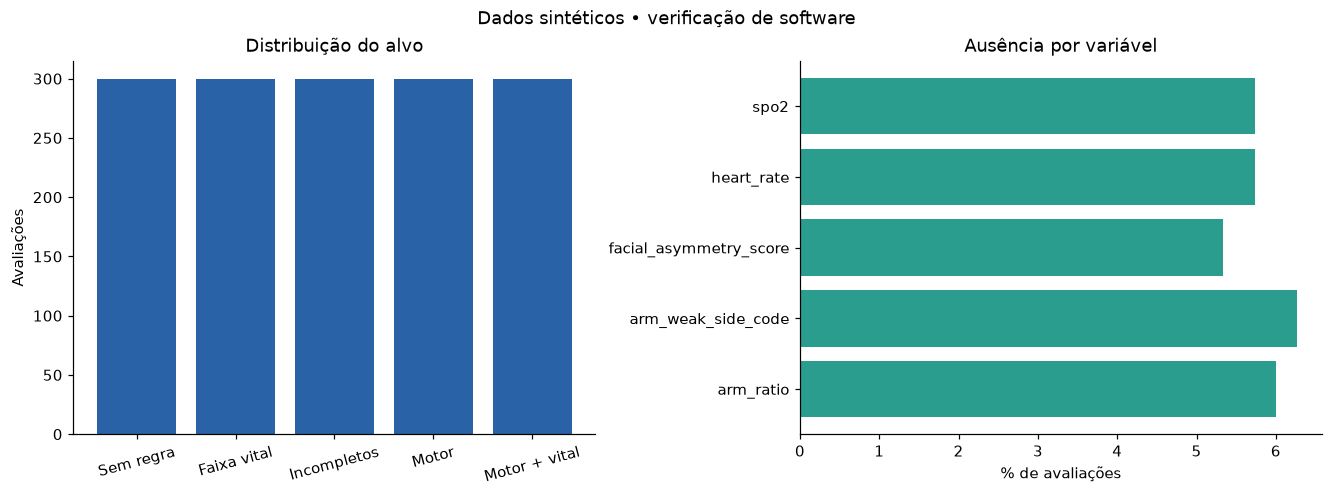

In [3]:
counts = Counter(y)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), layout="constrained")
axes[0].bar([display_label(c) for c in counts], counts.values(), color="#2962a6")
axes[0].set(title="Distribuição do alvo", ylabel="Avaliações")
axes[0].tick_params(axis="x", labelrotation=15)
axes[1].barh(FEATURE_NAMES, np.isnan(X).mean(axis=0) * 100, color="#2a9d8f")
axes[1].set(title="Ausência por variável", xlabel="% de avaliações")
fig.suptitle("Dados sintéticos • verificação de software" if MODO_DEMONSTRACAO else "Exploração da base de desenvolvimento")
fig.savefig(ARTIFACT_DIR / f"{PREFIX}_dados.png", dpi=160, bbox_inches="tight")
plt.show()

## 3. Treino e avaliação sem compartilhar pacientes

Uma floresta combina várias árvores treinadas com amostragem de registros e de
atributos. Aqui usamos `class_weight` para dar mais peso às classes pouco frequentes,
e buscamos profundidade, tamanho mínimo de folhas e quantidade de árvores.
Não é necessário padronizar a escala das entradas para essa família de modelos.

Fluxo: **pacientes → treino (~80%) / teste (~20%) → CV apenas no treino → melhor pipeline → teste**.

- `StratifiedGroupKFold` mantém as avaliações de cada pessoa na mesma partição,
  tentando preservar a proporção das classes. O primeiro fold fixo é reservado;
  não escolhemos a divisão que produz o melhor resultado.
- Medianas e indicadores de ausência são aprendidos dentro do pipeline em cada
  fold. Não fazemos imputação ou balanceamento sobre o conjunto completo.
- A busca usa balanced accuracy; todas as classes precisam existir nos subconjuntos.
  Se faltarem participantes, a execução para com uma mensagem explicativa.
- `DummyClassifier` sempre prevê a classe mais frequente e fornece uma comparação mínima.

Referências técnicas: [partição por grupo](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html)
e [prevenção de vazamento com pipelines](https://scikit-learn.org/stable/common_pitfalls.html).
O desvio padrão de CV e da permutação não é intervalo de confiança clínica.

In [4]:
result = train_evaluate(
    X, y, groups, random_state=RANDOM_STATE, n_iter=N_ITER,
    cv_splits=CV_SPLITS, test_splits=TEST_SPLITS,
)
pipeline = result["pipeline"]
report = result["report"]
train_idx, test_idx = result["train_indices"], result["test_indices"]
assert not set(groups[train_idx]) & set(groups[test_idx])

table(["Partição", "Avaliações", "Participantes"], [
    ["Treino (inclui CV)", len(train_idx), len(np.unique(groups[train_idx]))],
    ["Teste reservado", len(test_idx), len(np.unique(groups[test_idx]))],
])
print("Balanced accuracy média na CV:", round(report["cv_best_balanced_accuracy"], 4))
print("Parâmetros escolhidos:", report["best_params"])
table(["Posição", "Média CV", "Desvio CV", "Parâmetros"],
      [(r["rank"], f'{r["mean_balanced_accuracy"]:.3f}', f'{r["std_balanced_accuracy"]:.3f}', r["params"])
       for r in sorted(result["cv_results"], key=lambda r: r["rank"])])

Partição,Avaliações,Participantes
Treino (inclui CV),1200,600
Teste reservado,300,150


Balanced accuracy média na CV: 0.9708
Parâmetros escolhidos: {'forest__n_estimators': 200, 'forest__min_samples_leaf': 2, 'forest__max_features': 'sqrt', 'forest__max_depth': 12, 'forest__class_weight': 'balanced'}


Posição,Média CV,Desvio CV,Parâmetros
1,0.971,0.008,"{'forest__n_estimators': 200, 'forest__min_samples_leaf': 2, 'forest__max_features': 'sqrt', 'forest__max_depth': 12, 'forest__class_weight': 'balanced'}"
2,0.945,0.007,"{'forest__n_estimators': 300, 'forest__min_samples_leaf': 2, 'forest__max_features': None, 'forest__max_depth': None, 'forest__class_weight': 'balanced_subsample'}"
3,0.943,0.006,"{'forest__n_estimators': 100, 'forest__min_samples_leaf': 2, 'forest__max_features': None, 'forest__max_depth': None, 'forest__class_weight': 'balanced'}"
4,0.915,0.018,"{'forest__n_estimators': 100, 'forest__min_samples_leaf': 8, 'forest__max_features': 'sqrt', 'forest__max_depth': 12, 'forest__class_weight': 'balanced_subsample'}"
5,0.913,0.004,"{'forest__n_estimators': 100, 'forest__min_samples_leaf': 4, 'forest__max_features': None, 'forest__max_depth': None, 'forest__class_weight': 'balanced'}"
6,0.795,0.012,"{'forest__n_estimators': 200, 'forest__min_samples_leaf': 2, 'forest__max_features': None, 'forest__max_depth': 4, 'forest__class_weight': 'balanced_subsample'}"
7,0.777,0.008,"{'forest__n_estimators': 300, 'forest__min_samples_leaf': 8, 'forest__max_features': None, 'forest__max_depth': 4, 'forest__class_weight': 'balanced_subsample'}"
8,0.770,0.029,"{'forest__n_estimators': 100, 'forest__min_samples_leaf': 8, 'forest__max_features': None, 'forest__max_depth': 4, 'forest__class_weight': 'balanced'}"


## 4. Resultados no teste reservado

Balanced accuracy calcula a média do recall das classes; F1 macro equilibra
precisão e recall dando o mesmo peso a cada classe. Sensibilidade e especificidade
abaixo são calculadas **uma classe contra todas as demais**. Average precision
resume precisão/recall ao variar o limiar, e ROC-AUC resume a ordenação dos escores.

Cada avaliação recebe o mesmo peso: participantes com mais avaliações contribuem
mais para essas métricas. A separação por pessoa evita compartilhar participantes,
mas não substitui validação externa, análise por subgrupos ou avaliação da calibração.
Os rótulos da demonstração foram produzidos pelas regras sobre as mesmas entradas;
sensibilidade e especificidade abaixo se referem a essas classes sintéticas.
Elas não estimam sensibilidade/especificidade para AVC. A divisão por grupo não
remove essa circularidade: mede apenas generalização dentro do simulador.

Modelo,accuracy,balanced_accuracy,f1_macro,roc_auc_ovr_macro,average_precision_ovr_macro
random_forest,0.970,0.970,0.970,0.999,0.998
dummy,0.200,0.200,0.067,0.500,0.200


Classe,Precisão,Recall / sensibilidade,Especificidade,F1,Suporte
DEMO_DADOS_INCOMPLETOS,1.000,0.933,1.000,0.966,60
DEMO_FAIXA_VITAL,0.967,0.967,0.992,0.967,60
DEMO_MOTOR_E_VITAL,0.966,0.950,0.992,0.958,60
DEMO_SEM_REGRA_ACIONADA,0.968,1.000,0.992,0.984,60
DEMO_SINAL_MOTOR,0.952,1.000,0.988,0.976,60


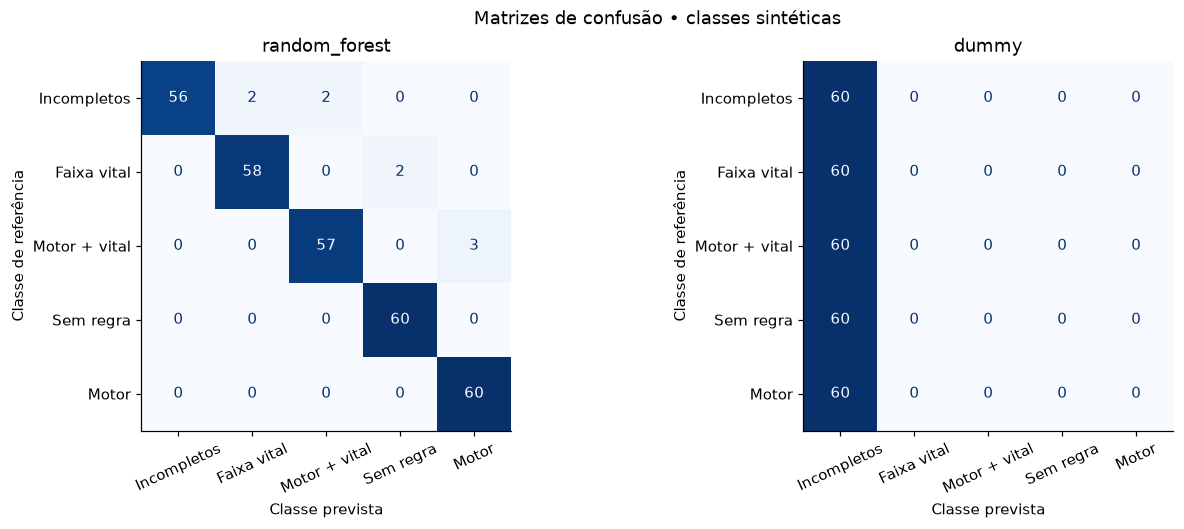

In [5]:
metric_names = ["accuracy", "balanced_accuracy", "f1_macro", "roc_auc_ovr_macro", "average_precision_ovr_macro"]
table(["Modelo", *metric_names],
      [[name, *[f'{metrics[key]:.3f}' for key in metric_names]]
       for name, metrics in report["test"].items()])
rf = report["test"]["random_forest"]
table(["Classe", "Precisão", "Recall / sensibilidade", "Especificidade", "F1", "Suporte"],
      [[label, f'{rf["classification_report"][label]["precision"]:.3f}',
        f'{values["sensitivity"]:.3f}', f'{values["specificity"]:.3f}',
        f'{rf["classification_report"][label]["f1-score"]:.3f}', values["support"]]
       for label, values in rf["per_class"].items()])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.7), layout="constrained")
for ax, (name, metrics) in zip(axes, report["test"].items()):
    ConfusionMatrixDisplay(np.asarray(metrics["confusion_matrix"]), display_labels=[display_label(c) for c in metrics["classes"]]).plot(
        ax=ax, colorbar=False, cmap="Blues", xticks_rotation=25,
    )
    ax.set(title=name, xlabel="Classe prevista", ylabel="Classe de referência")
fig.suptitle("Matrizes de confusão • " + ("classes sintéticas" if MODO_DEMONSTRACAO else "teste interno"))
fig.savefig(ARTIFACT_DIR / f"{PREFIX}_confusao.png", dpi=160, bbox_inches="tight")
plt.show()

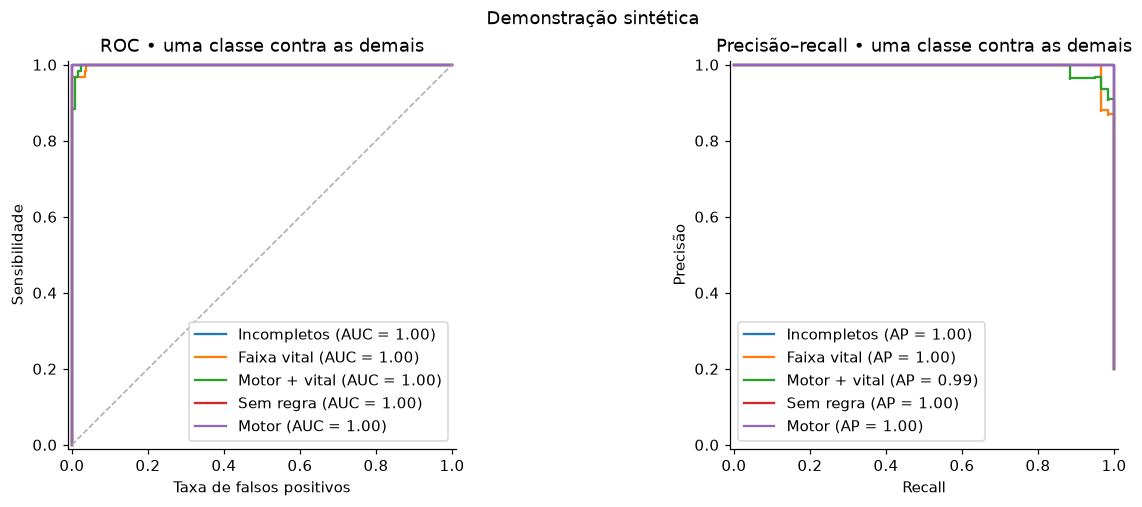

In [6]:
probabilities = pipeline.predict_proba(X[test_idx])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
for index, label in enumerate(pipeline.classes_):
    truth = (y[test_idx] == label).astype(int)
    RocCurveDisplay.from_predictions(truth, probabilities[:, index], name=display_label(label), ax=axes[0])
    PrecisionRecallDisplay.from_predictions(truth, probabilities[:, index], name=display_label(label), ax=axes[1])
axes[0].plot([0, 1], [0, 1], "--", color="#aaa", linewidth=1)
axes[0].set(title="ROC • uma classe contra as demais", xlabel="Taxa de falsos positivos", ylabel="Sensibilidade")
axes[1].set(title="Precisão–recall • uma classe contra as demais", xlabel="Recall", ylabel="Precisão")
fig.suptitle("Demonstração sintética" if MODO_DEMONSTRACAO else "Teste interno — probabilidades não calibradas")
fig.savefig(ARTIFACT_DIR / f"{PREFIX}_curvas.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. Importância por permutação

Medimos quanto a balanced accuracy muda ao embaralhar cada entrada do teste.
Valores pequenos ou negativos são possíveis. A importância não prova causalidade,
e variáveis correlacionadas podem dividir a importância. Esta é uma análise posterior
à escolha do modelo: não reutilize o teste para decidir novas features ou hiperparâmetros.

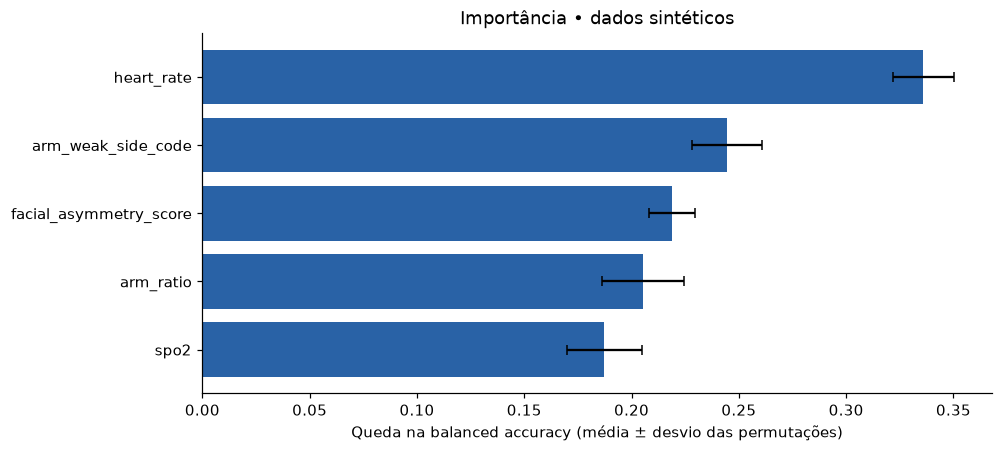

In [7]:
importance = result["permutation_importance"]
order = np.argsort(importance["mean"])
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
ax.barh(np.asarray(FEATURE_NAMES)[order], np.asarray(importance["mean"])[order],
        xerr=np.asarray(importance["std"])[order], color="#2962a6", capsize=3)
ax.axvline(0, color="#aaa", linewidth=1)
ax.set(xlabel="Queda na balanced accuracy (média ± desvio das permutações)",
       title="Importância • " + ("dados sintéticos" if MODO_DEMONSTRACAO else "teste interno"))
fig.savefig(ARTIFACT_DIR / f"{PREFIX}_importancia.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. Exportação e compatibilidade com o aplicativo

Exportamos **o pipeline que foi avaliado**, ajustado somente no treino, junto com
nomes/ordem das features, versão do scikit-learn e procedência dos dados. O relatório
guarda versões, configuração e um hash da base, sem listar identificadores pessoais.
O hash auxilia rastreabilidade, mas não transforma dados sensíveis em dados anônimos.

Arquivos de demonstração vão para `artifacts/random_forest_regras_experimental.*`; dados reais
geram um candidato em `artifacts/random_forest_candidato.*`. Nenhum deles é ativado
automaticamente. Arquivos `joblib` executam código ao serem carregados: use somente
artefatos confiáveis, mantendo as mesmas versões de dependências no treino e no app.

In [8]:
fingerprint = hashlib.sha256()
fingerprint.update(np.ascontiguousarray(X, dtype="<f8").tobytes())
fingerprint.update(json.dumps([y.tolist(), groups.tolist()], ensure_ascii=False).encode("utf-8"))
metadata = {
    "data_kind": DATA_KIND, "target_description": TARGET_DESCRIPTION,
    "dataset_sha256": fingerprint.hexdigest(), "versions": VERSIONS,
    "evaluation": report, "trained_on": "training_partition_only",
}
if MODO_DEMONSTRACAO:
    metadata.update({
        "learning_task": "rule_imitation", "label_provenance": "synthetic_rules",
        "rule_version": RULE_VERSION, "rule_config": RULE_CONFIG, "source_urls": SOURCE_URLS,
        "diagnostic_performance_estimated": False,
    })
    # Somente cenários fictícios são escritos automaticamente em CSV.
    with (ARTIFACT_DIR / f"{PREFIX}_cenarios.csv").open("w", encoding="utf-8", newline="") as handle:
        writer = csv.writer(handle)
        writer.writerow(["patient_id", *FEATURE_NAMES, "risco"])
        for group, row, target in zip(groups, X, y):
            writer.writerow([group, *["" if np.isnan(v) else float(v) for v in row], target])
export_path = save_artifact(pipeline, ARTIFACT_DIR / f"{PREFIX}.joblib", metadata=metadata)
report_path = ARTIFACT_DIR / f"{PREFIX}_relatorio.json"
report_path.write_text(json.dumps({
    **metadata, "clinical_validation": False, "cv_results": result["cv_results"],
    "permutation_importance": importance,
}, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
(ARTIFACT_DIR / f"{PREFIX}_versoes.txt").write_text(
    "\n".join(f"{name}=={version}" for name, version in VERSIONS.items()) + "\n", encoding="utf-8",
)
print("Artefato:", export_path.relative_to(ROOT))
print("Relatório:", report_path.relative_to(ROOT))

# A única liberação de demo é explícita e local a esta verificação.
adapter = RiscoRandomForest(export_path, allow_demo=MODO_DEMONSTRACAO)
sample = dict(zip(FEATURE_NAMES, X[test_idx[0]]))
prediction = adapter.predict(sample)
assert prediction["risco"] == str(pipeline.predict(X[test_idx[:1]])[0])
np.testing.assert_allclose(
    [prediction["probabilidades"][str(label)] for label in pipeline.classes_],
    pipeline.predict_proba(X[test_idx[:1]])[0],
)
print("Round-trip de exportação/inferência: OK")
print(json.dumps(prediction, ensure_ascii=False, indent=2))
if MODO_DEMONSTRACAO:
    assert RiscoRandomForest(export_path).predict(sample)["risco"] == "indefinido"
    print("Proteção: o aplicativo rejeita a demonstração sintética por padrão.")

Artefato: artifacts\random_forest_regras_experimental.joblib
Relatório: artifacts\random_forest_regras_experimental_relatorio.json
Round-trip de exportação/inferência: OK
{
  "risco": "DEMO_FAIXA_VITAL",
  "confianca": 0.8310848997075756,
  "probabilidades": {
    "DEMO_DADOS_INCOMPLETOS": 0.03556282769303452,
    "DEMO_FAIXA_VITAL": 0.8310848997075756,
    "DEMO_MOTOR_E_VITAL": 0.019811803222377813,
    "DEMO_SEM_REGRA_ACIONADA": 0.1134715038597705,
    "DEMO_SINAL_MOTOR": 6.896551724137931e-05
  },
  "aviso": "IMITAÇÃO DE REGRAS — não estima presença ou ausência de AVC. DEMONSTRAÇÃO SINTÉTICA — classes artificiais. Classificação experimental, sem validação clínica. As probabilidades do modelo não são uma estimativa calibrada de risco de AVC."
}


Proteção: o aplicativo rejeita a demonstração sintética por padrão.


### Teste de limites — separado do ajuste e do teste aleatório

Este conjunto verifica deliberadamente pontos próximos a 0,6, 60/100 BPM e 95%.
Ele não representa uma população. As árvores podem aprender limiares um pouco
diferentes, porque treinam em amostras finitas. Reportamos divergências sem alterar
o modelo depois de observá-las. Nem mesmo concordância perfeita comprovaria detecção de AVC.

In [9]:
if MODO_DEMONSTRACAO:
    edge_X = np.asarray(list(product(
        [0.2, 0.5999, 0.6, 0.6001], [0, 1, 2], [0, 1, 2],
        [59.99, 60.0, 80.0, 100.0, 100.01], [94.99, 95.0, 98.0],
    )), dtype=float)
    edge_y = label_rule_scenarios(edge_X)
    edge_pred = pipeline.predict(edge_X)
    mismatches = np.flatnonzero(edge_y != edge_pred)
    stress = {
        "purpose": "Fidelidade em limites artificiais; não é teste clínico",
        "cases": len(edge_X), "disagreements": len(mismatches),
        "agreement": float(np.mean(edge_y == edge_pred)),
        "examples": [{"features": dict(zip(FEATURE_NAMES, edge_X[i].tolist())),
                      "rule_label": str(edge_y[i]), "model_label": str(edge_pred[i])}
                     for i in mismatches[:20]],
    }
    print(f"Concordância em {len(edge_X)} cenários de limite: {stress['agreement']:.1%}.")
    print(f"Divergências: {len(mismatches)}. A regra direta reproduz o alvo por construção.")
    table([*FEATURE_NAMES, "Regra", "Random Forest"],
          [[*edge_X[i], edge_y[i], edge_pred[i]] for i in mismatches[:12]])
    (ARTIFACT_DIR / f"{PREFIX}_limites.json").write_text(
        json.dumps(stress, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8",
    )
    assert adapter.predict({})["risco"] == "indefinido"
else:
    print("Teste de imitação das regras se aplica apenas à demonstração sintética.")

Concordância em 540 cenários de limite: 54.1%.
Divergências: 248. A regra direta reproduz o alvo por construção.


arm_ratio,arm_weak_side_code,facial_asymmetry_score,heart_rate,spo2,Regra,Random Forest
0.2,0.0,0.0,59.99,94.99,DEMO_FAIXA_VITAL,DEMO_SEM_REGRA_ACIONADA
0.2,0.0,0.0,59.99,95.0,DEMO_FAIXA_VITAL,DEMO_SEM_REGRA_ACIONADA
0.2,0.0,0.0,59.99,98.0,DEMO_FAIXA_VITAL,DEMO_SEM_REGRA_ACIONADA
0.2,0.0,0.0,60.0,94.99,DEMO_FAIXA_VITAL,DEMO_SEM_REGRA_ACIONADA
0.2,0.0,0.0,80.0,94.99,DEMO_FAIXA_VITAL,DEMO_SEM_REGRA_ACIONADA
0.2,0.0,0.0,100.0,94.99,DEMO_FAIXA_VITAL,DEMO_SEM_REGRA_ACIONADA
0.2,0.0,1.0,59.99,94.99,DEMO_MOTOR_E_VITAL,DEMO_SINAL_MOTOR
0.2,0.0,1.0,59.99,95.0,DEMO_MOTOR_E_VITAL,DEMO_SINAL_MOTOR
0.2,0.0,1.0,59.99,98.0,DEMO_MOTOR_E_VITAL,DEMO_SINAL_MOTOR
0.2,0.0,1.0,60.0,94.99,DEMO_MOTOR_E_VITAL,DEMO_SINAL_MOTOR


## 7. Integração no aplicativo e futura coleta real

O protótipo treinado já foi incluído em
`models/random_forest_regras_experimental.joblib`. O aplicativo o carrega em modo
experimental explícito por `core.random_forest_runtime.load_app_model()`, mostra
essa identificação na tela inicial e compara previsão e regra na etapa final.
O carregador genérico continua rejeitando dados sintéticos sem `allow_demo=True`.
A exportação deste notebook para `artifacts/` não substitui automaticamente a cópia
instalada em `models/`; revise o novo experimento antes de atualizá-la.

Para usar o modelo atualmente incluído:
```python
from core.random_forest_runtime import load_app_model
modelo_demo = load_app_model()
```

A opção `ATIVAR_NO_APP` abaixo continua destinada ao candidato de dados reais,
no caminho separado `models/random_forest_risco.joblib`.

Quando houver rótulos independentes e resultados revisados, execute novamente com
dados reais. `ATIVAR_NO_APP=True` salva o pipeline avaliado no caminho que o aplicativo
carrega. A variável permanece desligada na entrega, e dados sintéticos são bloqueados
mesmo se essa opção for ligada. Reinicie o aplicativo após exportar um candidato real.

```python
from core.random_forest_model import RiscoRandomForest
modelo = RiscoRandomForest()  # models/random_forest_risco.joblib
resultado = modelo.predict(features)  # mesmo dicionário que a tela final envia
```

O retorno preserva `risco`, `confianca` e `aviso`, acrescentando `probabilidades`.
`confianca` é a maior saída de `predict_proba`, não certeza diagnóstica.
Sem modelo ou sem qualquer medição, o resultado é `indefinido`. Ausências parciais
são imputadas e informadas no aviso. Essa capacidade precisa ser validada com os
padrões reais de falta de dados antes de uso clínico.

In [10]:
if ATIVAR_NO_APP:
    if MODO_DEMONSTRACAO or DATA_KIND != "real":
        raise ValueError("Não é permitido ativar o modelo sintético no aplicativo.")
    if DEFAULT_MODEL_PATH.exists():
        raise FileExistsError("Já existe um modelo ativo. Preserve uma cópia e faça a troca deliberadamente.")
    save_artifact(pipeline, DEFAULT_MODEL_PATH, metadata=metadata)
    print("Candidato experimental instalado. Reinicie o aplicativo para carregá-lo.")
else:
    print("Ativação desligada. O artefato permanece em artifacts/.")

Ativação desligada. O artefato permanece em artifacts/.


## 8. Antes do próximo experimento

1. Definir desfecho, classes, instante de referência e processo de anotação com
   profissionais; preservar a separação entre atributo medido e resultado de referência.
2. Coletar participantes diversos, inclusive condições que possam confundir os motores
   de visão. Registrar versão de firmware, câmera, modelos e protocolo de aquisição.
3. Manter todas as sessões de uma pessoa no mesmo grupo. Para generalização entre
   unidades ou no tempo, reservar também locais/períodos independentes.
4. Planejar análise de erros, subgrupos, calibração e critérios de uso antes de olhar
   repetidamente o teste. Alterações após inspecioná-lo exigem nova avaliação independente.

O notebook entregue contém somente saídas sintéticas. Ao executar com dados reais,
revise e limpe as saídas antes de compartilhar o arquivo:
```powershell
.\.venv\Scripts\python.exe -m jupyter nbconvert --clear-output --inplace notebooks/random_forest_neurotriagem.ipynb
```
Leia o guia [`RANDOM_FOREST.md`](../RANDOM_FOREST.md) para comandos e estrutura dos arquivos.